# Pricing Model for Sublimation Print Orders
**Author:** YANA ATANASOVA

**Course:** Final Exam Project

## 1. Title & Introduction
When I price a custom sublimation print order (mugs, t-shirts, mousepads,
invitations), I need to know how much it actually costs me: blanks, ink,
paper, press time, design time and wasted items. Pricing by gut feeling often
leads to losing money on small orders or being too expensive on large ones.

In this project I build a **linear regression model** that predicts the
cost of an order from its characteristics, and then use it to recommend a
selling price with a profit margin.

The reader will see how a statistical model is built step by step: cleaning
the data, exploring it, deriving the mathematics of least squares, fitting
the model with matrices and with libraries, checking its quality, and
turning the result into a practical price calculator.

*Note: the dataset used here is simulated, because I did not have enough
structured records of real orders. The method can be applied to real data
without changes.*

In [1]:
# %pip install pandas numpy matplotlib statsmodels scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Problem Formulation
**Real-world problem.** Given the details of a print order, estimate how
much it costs me to produce, so I can set a price that covers the cost and
leaves a profit.

**Mathematical formulation.** Let $y$ be the total cost of an order (in EUR).
It depends on $n$ measurable characteristics of the order:

- $x_1$ = quantity
- $x_2$ = ink used (ml)
- $x_3$ = paper sheets
- $x_4$ = press time (min)
- $x_5$ = design time (min)
- $x_6$ = waste (%)

We assume that the cost is approximately a linear function of these
variables:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_6 x_6 + \varepsilon$$

where $\beta_0$ is the base cost, $\beta_j$ is the extra cost for one more
unit of $x_j$, and $\varepsilon$ is a random error that we cannot explain.

**Goal.** Estimate the unknown coefficients $\beta_0, \dots, \beta_6$ from
the data, so that for a new order we can compute a predicted cost $\hat y$
and a recommended price

$$\text{price} = \hat y \cdot (1 + m),$$

where $m$ is the desired profit margin (for example $m = 0.3$ means 30%).

**Assumptions.**
1. The relationship between cost and the variables is approximately linear.
2. The errors $\varepsilon$ are independent, have mean zero and constant
   variance.
3. The errors are approximately normally distributed.
4. The data represent typical orders (no unusual special cases).
5. Prices of materials (blanks, ink, paper) and the cost per minute of work
   stay constant during the period covered by the data.

**Limitations.** The data are simulated, so the model reflects the
simulation rules and not a real workshop. The linear model may also miss
effects such as discounts for large quantities.

## 3. Mathematical Background
**Matrix form.** Suppose we have $N$ orders. We collect the predictors in a
matrix $X$ of size $N \times (p+1)$, where each row is one order and the
first column is all ones (it corresponds to $\beta_0$). The costs form a
vector $y$ and the coefficients a vector $\beta$. The model becomes

$$y = X\beta + \varepsilon.$$

**Ordinary Least Squares (OLS).** We choose $\beta$ so that the predictions
$X\beta$ are as close as possible to $y$, by minimizing the sum of squared
errors:

$$S(\beta) = \|y - X\beta\|^2 = (y - X\beta)^T (y - X\beta).$$

To find the minimum, we take the derivative with respect to $\beta$ and set
it to zero:

$$\frac{\partial S}{\partial \beta} = -2X^T y + 2X^T X \beta = 0
\quad\Longrightarrow\quad X^T X \beta = X^T y.$$

If the columns of $X$ are linearly independent, $X^T X$ is invertible and

$$\hat\beta = (X^T X)^{-1} X^T y.$$

**Residuals.** The fitted values are $\hat y = X\hat\beta$ and the residuals
are $e_i = y_i - \hat y_i$. A good model has small residuals without any
visible pattern.

**Coefficient of determination.** $R^2$ measures what fraction of the
variation in the costs the model explains:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

It is between 0 and 1, and values close to 1 mean a good fit.

**Model assumptions.** OLS gives reliable results when the assumptions from
Section 2 hold: linearity, independent errors with mean zero and constant
variance, and approximately normal errors. We check them in Section 7 using
residual plots.

**Ridge regression.** When predictors are strongly correlated (for example,
ink used and quantity), the coefficients of OLS can become unstable. Ridge
regression adds a penalty for large coefficients:

$$\hat\beta_{ridge} = \arg\min_\beta \; \|y - X\beta\|^2 + \lambda \sum_{j=1}^{p} \beta_j^2
\quad\Longrightarrow\quad \hat\beta_{ridge} = (X^T X + \lambda I)^{-1} X^T y,$$

where $\lambda \ge 0$ controls the strength of the penalty.
For $\lambda = 0$ we get OLS back. For simplicity the closed form above assumes that the data are centered, so the intercept is not penalized. We compare both methods in Section 8.

## 4. Data

**Source.** The dataset is **simulated**. I did not have enough structured
records of real orders, so I generated 60 orders with the script
`generate_data.py`. Each order's cost is computed from a known formula
(prices of blanks, ink, paper and labor) plus a small random noise. This
means the model can be tested in a controlled setting, but the results
describe the simulation and not a real workshop.

**Columns.**

| Column | Description |
|---|---|
| `order_id` | Unique number of the order |
| `product_type` | Product: mug, t-shirt, mousepad, phone case or invitation |
| `quantity` | Number of items in the order |
| `area_cm2` | Printed area of one item (cm²) |
| `ink_ml` | Ink used for the whole order (ml) |
| `paper_sheets` | Sublimation paper sheets used |
| `press_time_min` | Time in the heat press (minutes) |
| `design_time_min` | Time spent on the design (minutes) |
| `waste_pct` | Percentage of items wasted (misprints) |
| `total_cost_eur` | **Target variable:** total cost of the order (EUR) |

**Data problems on purpose.** To practice data cleaning, a few missing
values and one outlier were added to the simulated data. The cleaning steps
are shown below.

In [11]:
df = pd.read_csv("orders.csv")
df.head()

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
0,1,mug,19,179.2,9.15,6,36.2,88.0,5.3,68.36
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23
2,3,mug,14,180.8,6.88,5,41.9,38.0,8.1,49.54
3,4,phone_case,10,57.9,1.52,1,22.3,65.0,10.4,45.08
4,5,mousepad,7,413.4,7.68,6,16.9,48.0,2.9,25.74


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         60 non-null     int64  
 1   product_type     60 non-null     str    
 2   quantity         60 non-null     int64  
 3   area_cm2         60 non-null     float64
 4   ink_ml           58 non-null     float64
 5   paper_sheets     60 non-null     int64  
 6   press_time_min   60 non-null     float64
 7   design_time_min  58 non-null     float64
 8   waste_pct        58 non-null     float64
 9   total_cost_eur   60 non-null     float64
dtypes: float64(6), int64(3), str(1)
memory usage: 4.8 KB


In [6]:
df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             2
paper_sheets       0
press_time_min     0
design_time_min    2
waste_pct          2
total_cost_eur     0
dtype: int64

In [17]:
for col in ["ink_ml", "waste_pct", "design_time_min"]:
    df[col] = df[col].fillna(df.groupby("product_type")[col].transform("median"))
    df.isna().sum()

In [7]:
df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             2
paper_sheets       0
press_time_min     0
design_time_min    2
waste_pct          2
total_cost_eur     0
dtype: int64

In [8]:
df["cost_per_unit"] = df["total_cost_eur"] / df["quantity"]
median = df.groupby("product_type")["cost_per_unit"].transform("median")
df["ratio"] = df["cost_per_unit"] / median
df.sort_values("ratio", ascending=False).head(5)

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur,cost_per_unit,ratio
30,31,phone_case,8,56.8,1.04,1,27.4,46.0,10.3,104.91,13.113750,2.766760
52,53,t-shirt,1,645.0,1.57,2,7.5,77.0,4.8,19.00,19.000000,1.980714
50,51,phone_case,2,61.4,0.32,1,8.4,72.0,7.1,18.04,9.020000,1.903054
47,48,mousepad,3,554.7,4.07,3,12.1,65.0,5.3,19.24,6.413333,1.857879
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23,6.410000,1.856914


In [9]:
df_clean = df[df["ratio"] < 2].drop(columns=["cost_per_unit", "ratio"])
print(df_clean.shape)
df_clean.to_csv("orders_clean.csv", index=False)

(59, 10)


Missing values in ink_ml, waste_pct and design_time_min were filled with the median of the 
same product type. One order with an unusually high cost per unit was removed as an outlier.

## 5. Exploratory Analysis

Before building a model, we look at the data. For each numeric variable we compute the mean $\bar x = \frac{1}{N}\sum_i x_i$, the standard deviation $s = \sqrt{\frac{1}{N-1}\sum_i (x_i-\bar x)^2}$ and the quartiles (the values below which 25%, 50% and 75% of the observations lie).

In [10]:
df_clean.describe().round(2)

,order_id,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
count,59.00,59.00,59.00,57.00,59.00,59.00,57.00,57.00,59.00
mean,30.49,18.49,283.28,14.51,9.88,45.75,54.96,5.01,39.06
std,17.61,23.30,175.89,22.57,13.08,52.01,23.70,2.58,20.18
min,1.00,1.00,52.50,0.31,1.00,7.50,12.00,0.00,10.48
25%,15.50,4.50,122.25,1.69,1.50,15.65,35.00,3.30,23.04
50%,30.00,10.00,302.00,7.20,5.00,29.10,56.00,5.10,36.37
75%,45.50,18.50,416.80,17.57,13.00,49.65,74.00,6.60,52.93
max,60.00,117.00,645.00,134.04,66.00,284.80,90.00,10.40,99.14


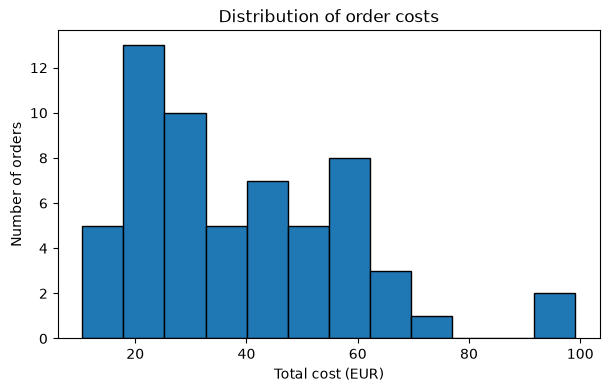

In [12]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["total_cost_eur"], bins=12, edgecolor="black")
plt.xlabel("Total cost (EUR)")
plt.ylabel("Number of orders")
plt.title("Distribution of order costs")
plt.show()

The histogram shows that the cost of an order varies a lot. Most orders are small: more than half cost less than 40 EUR, and the largest group is between 20 and 30 EUR. There is a second, smaller group of orders around 50-70 EUR, and only a few orders cost more than 70 EUR. The average cost is about 39 EUR, but the median is lower (about 36 EUR), because a few expensive orders pull the average up. This wide spread is a reason why a single flat price for every order would not work, and why it is useful to model the cost from the order's characteristics.

### Correlations

To see which variables are related, we use the Pearson correlation coefficient between two variables $x$ and $y$:

$$r = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2 \,\sum_i (y_i-\bar y)^2}}.$$

It is always between $-1$ and $1$. Values close to $1$ mean that the variables grow together, values close to $-1$ 
mean that one grows when the other falls, and values close to $0$ mean no linear relationship.

In [18]:
cols = ["quantity", "area_cm2", "ink_ml", "paper_sheets",
        "press_time_min", "design_time_min", "waste_pct", "total_cost_eur"]
corr = df_clean[cols].corr().round(2)
corr

,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
quantity,1.00,0.11,0.95,0.97,0.99,-0.06,-0.03,0.59
area_cm2,0.11,1.00,0.26,0.27,0.10,0.15,-0.14,0.12
ink_ml,0.95,0.26,1.00,0.98,0.95,0.01,-0.05,0.59
paper_sheets,0.97,0.27,0.98,1.00,0.95,-0.01,-0.06,0.59
press_time_min,0.99,0.10,0.95,0.95,1.00,-0.03,-0.06,0.61
design_time_min,-0.06,0.15,0.01,-0.01,-0.03,1.00,-0.12,0.35
waste_pct,-0.03,-0.14,-0.05,-0.06,-0.06,-0.12,1.00,-0.17
total_cost_eur,0.59,0.12,0.59,0.59,0.61,0.35,-0.17,1.00


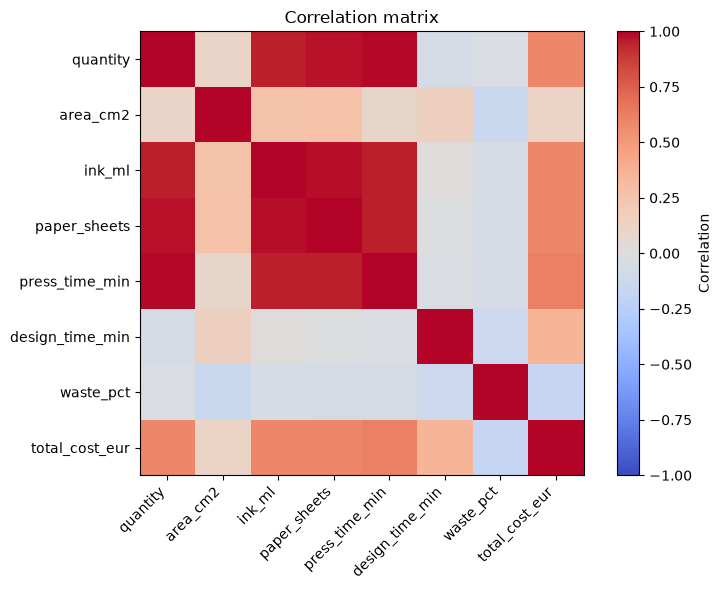

In [19]:
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

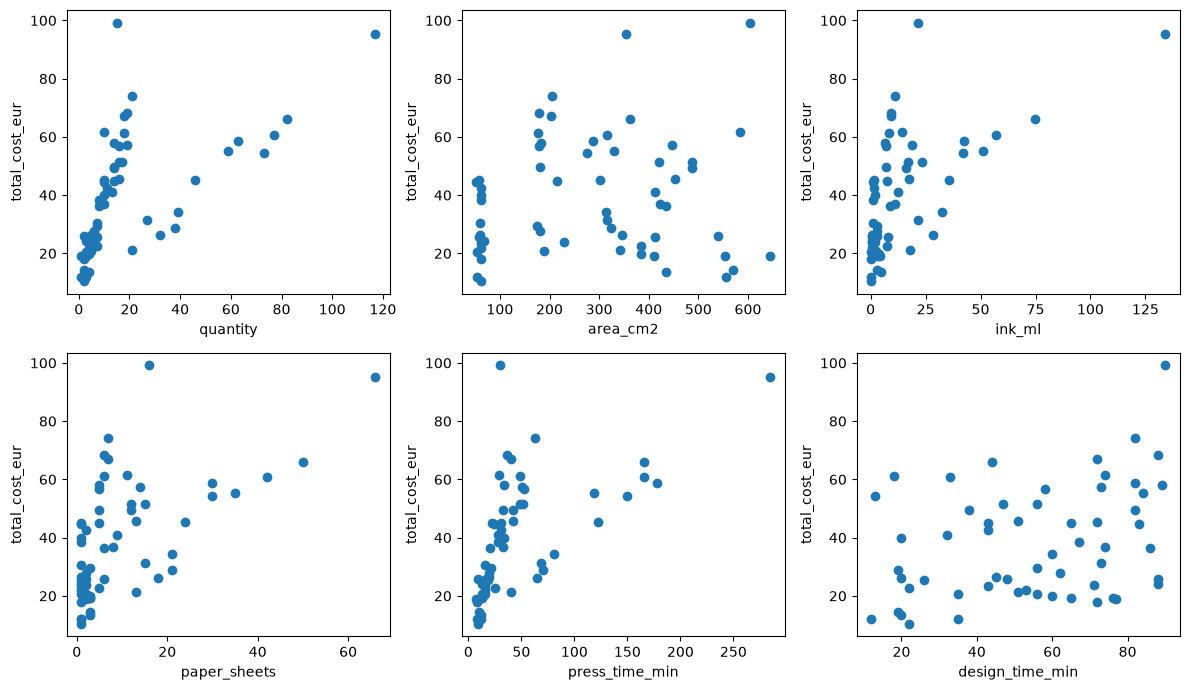

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, cols[:-1][:6]):
    ax.scatter(df_clean[col], df_clean["total_cost_eur"])
    ax.set_xlabel(col)
    ax.set_ylabel("total_cost_eur")
plt.tight_layout()
plt.show()

In [22]:
cols = ["quantity", "area_cm2", "ink_ml", "paper_sheets",
        "press_time_min", "design_time_min", "waste_pct", "total_cost_eur"]
corr = df_clean[cols].corr().round(2)
corr

,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
quantity,1.00,0.11,0.95,0.97,0.99,-0.06,-0.03,0.59
area_cm2,0.11,1.00,0.26,0.27,0.10,0.15,-0.14,0.12
ink_ml,0.95,0.26,1.00,0.98,0.95,0.01,-0.05,0.59
paper_sheets,0.97,0.27,0.98,1.00,0.95,-0.01,-0.06,0.59
press_time_min,0.99,0.10,0.95,0.95,1.00,-0.03,-0.06,0.61
design_time_min,-0.06,0.15,0.01,-0.01,-0.03,1.00,-0.12,0.35
waste_pct,-0.03,-0.14,-0.05,-0.06,-0.06,-0.12,1.00,-0.17
total_cost_eur,0.59,0.12,0.59,0.59,0.61,0.35,-0.17,1.00


The correlation matrix shows that `quantity`, `ink_ml`, `paper_sheets` and `press_time_min` are almost perfectly correlated with each other (0.95-0.99). This is expected: a bigger order needs more ink, more paper and more time in the press. Such strongly related predictors can make the coefficients of ordinary least squares unstable, which is why we also try Ridge regression later.

The correlation of each of these variables with the total cost is only about 0.6, because the orders are made of different products with different prices of blanks. Design time has a weaker relationship with cost (0.35), the printed area has almost none (0.12), and the waste percentage is very weakly and negatively correlated (-0.17), which is most likely just random variation in a small sample.

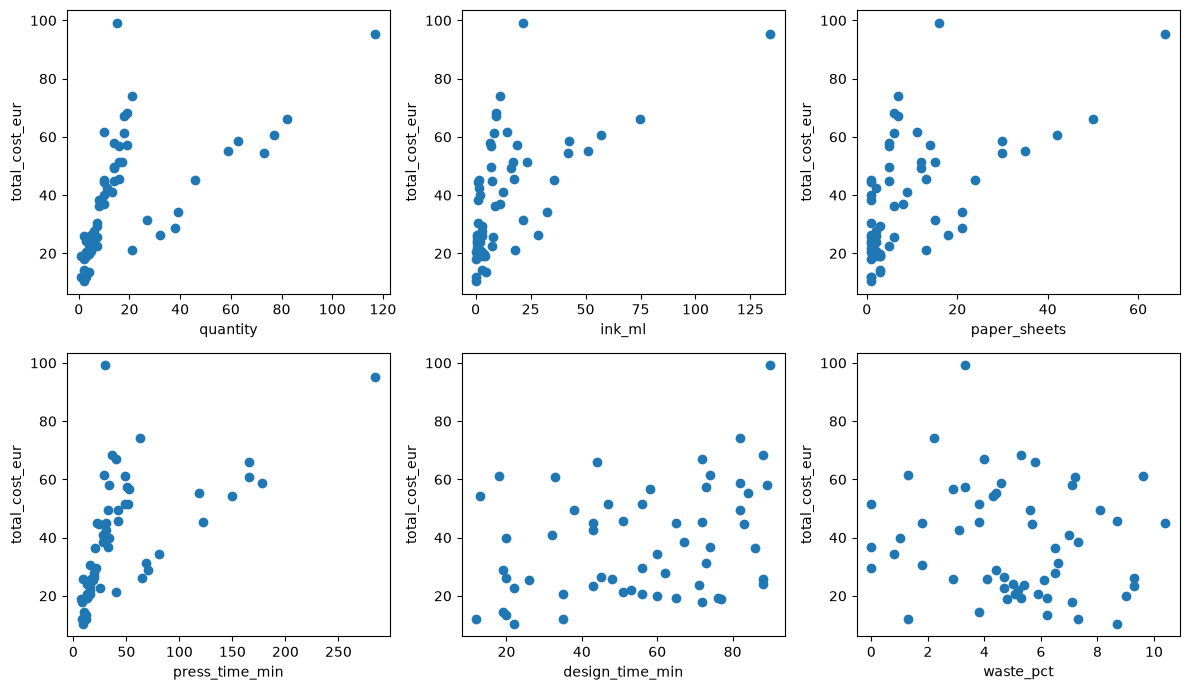

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, ["quantity", "ink_ml", "paper_sheets",
                               "press_time_min", "design_time_min", "waste_pct"]):
    ax.scatter(df_clean[col], df_clean["total_cost_eur"])
    ax.set_xlabel(col)
    ax.set_ylabel("total_cost_eur")
plt.tight_layout()
plt.show()

## 6. Modeling
*TODO: Simple regression, then multiple regression. Interpret the coefficients.*

## 7. Model Diagnostics
*TODO: Residual plots, normality, homoscedasticity, cross-validation.*

## 8. Comparison of Methods
*TODO: OLS vs Ridge. Metrics: RMSE, MAE, $R^2$.*

## 9. Price Calculator
*TODO: A function that takes order parameters and returns a recommended price with a profit margin.*

In [12]:
def recommend_price(order, model, margin=0.3):
    """Return the recommended price for an order."""
    raise NotImplementedError

## 10. Conclusions & Next Steps
*TODO: Findings, limitations, possible improvements.*

## 11. References
The notebook structure and the simulated data generator were created with the help of an AI 
assistant (Claude). The analysis and conclusions are my own.